# 01 · Explorative Datenanalyse

Bevor wir Netzwerke bauen, wollen wir wissen, was in unserem Datensatz steckt und wo er Lücken hat.
Grundlage ist der Crawl von 20min.ch (`data/articles.sqlite`). Daraus haben wir mit `data_extraction.keywords`
die Keywords und mit `data_extraction.autoren` die Personen gebildet. Die Artikel stammen aus den Jahren 2020 bis 2026.

Wo wir auf ein Problem stossen, notieren wir, wie wir in den Netzwerk-Notebooks damit umgehen.
Die Liste dieser Massnahmen steht am Schluss.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd()))  # Notebook liegt in src/
import daten
import grafik
import netzwerk as nw

# Hauptdatenbank, sobald Keywords und Personen gebildet sind, sonst die Kopie
# data/articles_snapshot.sqlite. Andere Datenbank: Umgebungsvariable SAN_DB.
DB = daten.standard_db()
GRAPHEN = daten.ROOT / "Graphen"

grafik.stil()
pd.set_option("display.max_colwidth", 100)
print("Datenbank:", DB)

WOCHENTAGE = ["Mo", "Di", "Mi", "Do", "Fr", "Sa", "So"]

Datenbank: C:\Users\elias\Desktop\FHNW\SAN\SAN_20_Minuten\data\articles.sqlite


In [2]:
alle = daten.load_articles(DB, alle_status=True)
artikel = daten.load_articles(DB)
roh = daten.load_articles(DB, reaktionen_vor_start=True)  # Rohwerte, nur für Abschnitt 7
keywords = daten.load_keywords(DB)
personen = daten.load_persons(DB, rollen=("autor", "quelle"))
autoren_roh = daten.load_table(DB, "article_authors")
quellen_roh = daten.load_table(DB, "article_kuerzel")

# Für Auswertungen der Reaktionen: ab Juni 2020 und ohne Liveticker (siehe Abschnitte 3 und 7)
reaktiv = artikel[artikel["reaktionen_gueltig"] & ~artikel["ticker"]]

print(f"Artikel:                 {len(artikel):>9,}   ({artikel['datum'].min():%d.%m.%Y} bis {artikel['datum'].max():%d.%m.%Y})")
print(f"Keyword-Zuordnungen:     {len(keywords):>9,}")
print(f"Personen-Zuordnungen:    {len(personen):>9,}")
print(f"Artikel mit Reaktionen:  {len(reaktiv):>9,}")

Artikel:                   165,151   (01.01.2020 bis 05.11.2026)
Keyword-Zuordnungen:     1,308,572
Personen-Zuordnungen:      170,989
Artikel mit Reaktionen:    151,538


## 1. Wie vollständig ist der Crawl?

Fehlen ganze Monate oder konnte ein bestimmter Seitentyp nicht gelesen werden, dann fehlen diese Themen später
auch im Netz. Wir prüfen deshalb zuerst, wie viele URLs aus der Sitemap erfolgreich verarbeitet wurden und ob die
Artikel gleichmässig über die Zeit verteilt sind.

Wir rechnen damit, dass fast alle URLs funktionieren und die Fehler Sonderseiten ohne eigentlichen Artikel sind.
20 Minuten publiziert online grob 60 bis 80 Artikel pro Tag, also etwa 2'000 pro Monat.

In [3]:
status = alle["status"].value_counts()
pd.DataFrame({"URLs": status, "Anteil": (status / status.sum()).map("{:.2%}".format)})

,URLs,Anteil
status,,
done,165151,99.36%
failed,1034,0.62%
skipped,27,0.02%


In [4]:
fehler = alle[alle["status"] == "failed"]
print("HTTP-Status der fehlgeschlagenen URLs:")
print(fehler["http_code"].value_counts(dropna=False).head(6).to_string())
print("\nBeispiele:")
print(fehler["url"].sample(min(5, len(fehler)), random_state=1).to_string(index=False))

HTTP-Status der fehlgeschlagenen URLs:
http_code
200    868
308     75
504     52
502     38
307      1

Beispiele:
https://www.20min.ch/story/weil-am-rhein-de-massnahmengegner-demonstration-weil-am-rhein-24041921...
             https://www.20min.ch/story/so-ist-die-lage-an-den-europaeischen-flughaefen-941500265593
https://www.20min.ch/story/das-sagt-gastro-suisse-zu-den-corona-massnahmen-des-bundesrates-105758...
              https://www.20min.ch/story/mega-kaution-abgelehnt-diddy-muss-in-haft-bleiben-103334223
                 https://www.20min.ch/story/city-eliminiert-real-auch-juve-scheidet-aus-971901786502


11.2026 ist nur bis zum 06. enthalten und wird nicht gezeigt


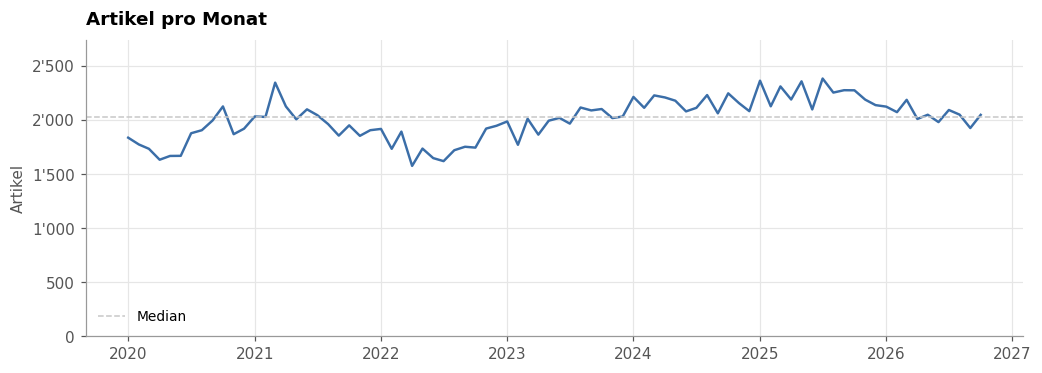

Median 2,031 Artikel pro Monat
Wenigste: 1,576 im 04.2022, meiste: 2,384 im 07.2025


In [5]:
pro_monat = artikel.groupby("monat").size()
pro_monat.index = pd.to_datetime(pro_monat.index)
# Der letzte Monat ist nur angebrochen (Crawl bis Anfang November 2026) und würde einen Einbruch vortäuschen
letzter_tag = artikel["datum"].max().tz_convert("Europe/Zurich")
if letzter_tag.day < 28:
    print(f"{letzter_tag:%m.%Y} ist nur bis zum {letzter_tag:%d.} enthalten und wird nicht gezeigt")
    pro_monat = pro_monat.iloc[:-1]

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(pro_monat.index, pro_monat.values, color=grafik.BLAU, linewidth=1.6)
ax.axhline(pro_monat.median(), color=grafik.GRAU, linestyle="--", linewidth=1, label="Median")
ax.set(title="Artikel pro Monat", ylabel="Artikel", ylim=(0, pro_monat.max() * 1.15))
ax.legend(loc="lower left")
grafik.tausender(ax)
plt.show()

print(f"Median {pro_monat.median():,.0f} Artikel pro Monat")
print(f"Wenigste: {pro_monat.min():,} im {pro_monat.idxmin():%m.%Y}, meiste: {pro_monat.max():,} im {pro_monat.idxmax():%m.%Y}")

Der Crawl ist praktisch vollständig: 99,4 % der URLs wurden verarbeitet. Die meisten der 1'034 Fehlschläge haben
HTTP-Status 200, die Seite war also erreichbar, enthielt aber keinen Artikel in der erwarteten Form. Die Beispiele sind
gewöhnliche Artikel-URLs. Ganz erklären können wir diese Fälle nicht. Ein kleiner Teil sind Weiterleitungen (308) und
Serverfehler (502, 504). Bei 165'000 Artikeln fällt das nicht ins Gewicht, und eine Häufung in bestimmten Monaten sehen wir nicht.

Pro Monat erscheinen rund 2'000 Artikel, wie erwartet. Die Zahl steigt von etwa 1'700 Anfang 2020 auf 2'200 bis 2'400 im Jahr 2025.
Im Frühling 2022 gibt es eine kurze Delle. Eine echte Lücke gibt es nicht. Weil die Jahre unterschiedlich gross sind,
vergleichen wir sie in Notebook 02 mit gleich vielen Artikeln pro Jahr.

## 2. Wann publiziert die Redaktion?

20 Minuten ist als Pendlerzeitung entstanden. Uns interessiert, ob man das im Online-Rhythmus noch sieht.
Für die Netzwerke ist das nur am Rand wichtig, es hilft aber, die Daten einzuordnen: Ein Artikel um 3 Uhr
nachts ist eher eine Agenturmeldung als eine eigene Recherche.

Wir erwarten einen Schwerpunkt am frühen Morgen und über den Tag, wenig in der Nacht und weniger Artikel am Wochenende.

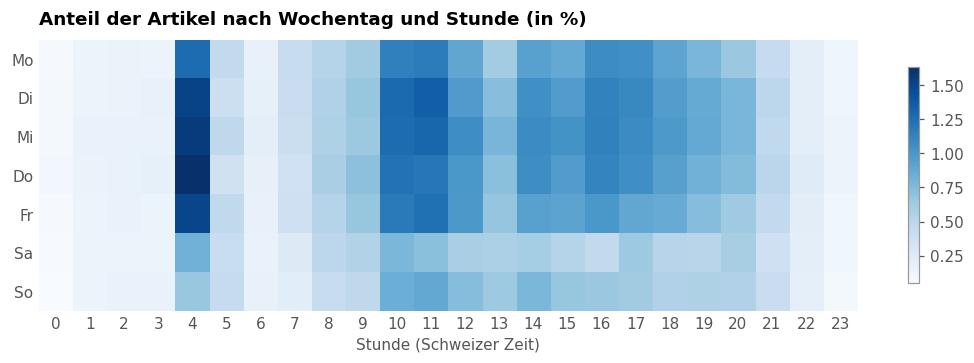

Stärkste Stunden: 4 Uhr (9.0%), 11 Uhr (7.9%), 10 Uhr (7.7%)
Zwischen 0 und 5 Uhr: 12.5%
Samstag und Sonntag: 21.3% (bei Gleichverteilung 28.6 %)


In [6]:
rhythmus = pd.crosstab(artikel["wochentag"], artikel["stunde"]).reindex(index=range(7), columns=range(24), fill_value=0)
rhythmus.index = WOCHENTAGE

fig, ax = plt.subplots(figsize=(12, 3.2))
grafik.heatmap(rhythmus / rhythmus.values.sum() * 100, ax=ax, fmt="", cmap="Blues", farbbalken=True,
               titel="Anteil der Artikel nach Wochentag und Stunde (in %)")
ax.set_xlabel("Stunde (Schweizer Zeit)")
plt.show()

pro_stunde = rhythmus.sum() / rhythmus.values.sum()
print("Stärkste Stunden:", ", ".join(f"{h} Uhr ({a:.1%})" for h, a in pro_stunde.nlargest(3).items()))
print(f"Zwischen 0 und 5 Uhr: {pro_stunde.loc[0:4].sum():.1%}")
print(f"Samstag und Sonntag: {rhythmus.loc[['Sa', 'So']].values.sum() / rhythmus.values.sum():.1%} (bei Gleichverteilung 28.6 %)")

Die Erwartung stimmt nur teilweise. Am frühen Morgen gibt es tatsächlich eine Spitze, aber sie ist viel schärfer als
gedacht: Um 4 Uhr erscheinen 9 % aller Artikel, mehr als in jeder anderen Stunde, um 3 und um 5 Uhr dagegen fast nichts.
Wir vermuten, dass die Redaktion die Artikel für den Morgen gesammelt freischaltet, damit sie bereitstehen, wenn die
Pendlerinnen und Pendler aufstehen. Über den Tag verteilt sich der Rest mit Schwerpunkten am späten Vormittag und am
Nachmittag. Am Wochenende erscheinen 21 % der Artikel, deutlich weniger als die 28,6 % bei gleichmässiger Verteilung.

## 3. Artikel und Liveticker

Ein Liveticker bündelt Dutzende Meldungen unter einer URL und bleibt oft tagelang offen. Er enthält dadurch viele
Themen und sammelt über lange Zeit Likes und Kommentare. Falls Ticker sich stark von normalen Artikeln unterscheiden,
müssen wir sie im Themennetz und bei den Reaktionen getrennt behandeln.

Wir erwarten nur wenige Prozent Ticker, mit mehr Tickern in Krisenzeiten (Corona 2020, Ukraine 2022), und deutlich
mehr Reaktionen pro Ticker als pro Artikel.

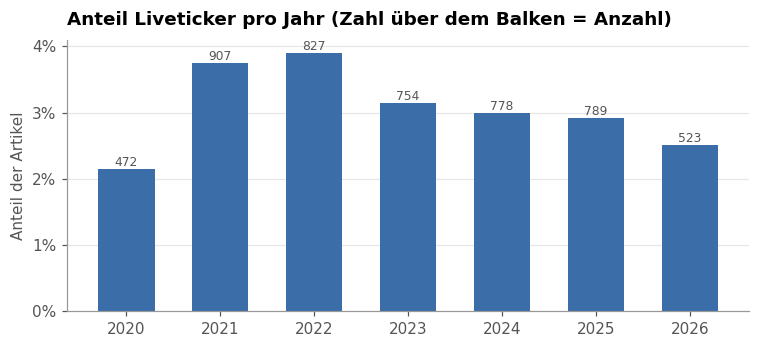

Median der Reaktionen (ab Juni 2020):


,likes,shares,kommentare
ticker,,,
Artikel,476.0,49.0,32.0
Liveticker,447.0,26.0,33.0


In [7]:
ticker_jahr = artikel.groupby("jahr")["ticker"].agg(anzahl="sum", anteil="mean")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(ticker_jahr.index.astype(str), ticker_jahr["anteil"], color=grafik.BLAU, width=0.6)
for x, (n, a) in enumerate(zip(ticker_jahr["anzahl"], ticker_jahr["anteil"])):
    ax.text(x, a, f"{n:,}".replace(",", "'"), ha="center", va="bottom", fontsize=8, color=grafik.DUNKELGRAU)
ax.set(title="Anteil Liveticker pro Jahr (Zahl über dem Balken = Anzahl)", ylabel="Anteil der Artikel")
grafik.prozent(ax)
ax.grid(axis="x", visible=False)
plt.show()

vergleich = artikel[artikel["reaktionen_gueltig"]].groupby("ticker")[["likes", "shares", "kommentare"]].median()
vergleich.index = vergleich.index.map({False: "Artikel", True: "Liveticker"})
print("Median der Reaktionen (ab Juni 2020):")
vergleich

Liveticker machen jedes Jahr nur 2 bis 4 % der Artikel aus. Den höchsten Anteil haben 2021 und 2022, den tiefsten aber
ausgerechnet 2020. Das passt nicht zur Erwartung, dass Corona viele Ticker ausgelöst hat. Möglicherweise hatte das alte
System Anfang 2020 Ticker noch nicht als eigenes Format gekennzeichnet.

Unsere zweite Erwartung hat sich nicht bestätigt: Im Median bekommen Ticker nicht mehr Likes oder Kommentare als normale
Artikel, nur weniger Shares. Für die Reaktionsauswertungen macht der Ausschluss also wenig aus. Wir behalten ihn trotzdem bei,
damit jede Einheit ein Artikel ist. Wichtig bleibt der Ausschluss im Themennetz, weil ein Ticker unter einer URL viele Themen
verbindet, die nichts miteinander zu tun haben.

## 4. Fehlende Werte

Ein leeres Feld kann drei Ursachen haben: einen Fehler im Crawler, einen Layoutwechsel bei 20 Minuten oder eine
Eigenschaft der Quelle selbst, zum Beispiel eine gesperrte Kommentarfunktion. Je nach Ursache gehen wir anders damit um.
Deshalb schauen wir uns die Lücken pro Jahr an: Ein Crawler-Fehler würde eher zufällig verteilt sein, ein Layoutwechsel
würde ab einem bestimmten Jahr auftreten.

Titel und Datum sollten immer vorhanden sein. Kommentare dürften oft fehlen, Likes und Shares vor Juni 2020
(siehe Abschnitt 7).

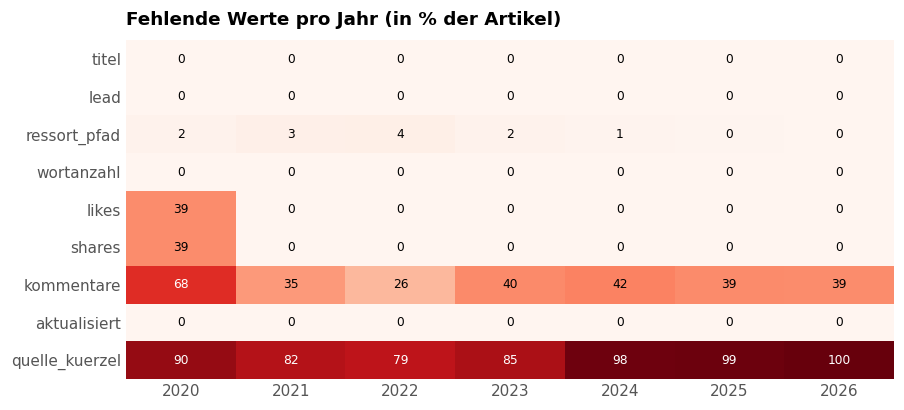

,fehlend insgesamt
quelle_kuerzel,90.6%
kommentare,41.4%
likes,5.2%
shares,5.2%
ressort_pfad,1.7%
lead,0.0%
titel,0.0%
wortanzahl,0.0%
aktualisiert,0.0%


In [8]:
spalten = ["titel", "lead", "ressort_pfad", "wortanzahl", "likes", "shares", "kommentare", "aktualisiert", "quelle_kuerzel"]
leer = artikel[spalten].apply(lambda s: s.isna() | (s.astype(str).str.strip() == ""))
pro_jahr = leer.groupby(artikel["jahr"]).mean().T

fig, ax = plt.subplots(figsize=(9, 4))
grafik.heatmap(pro_jahr * 100, ax=ax, fmt="{:.0f}", cmap="Reds", titel="Fehlende Werte pro Jahr (in % der Artikel)")
plt.show()

leer.mean().sort_values(ascending=False).map("{:.1%}".format).to_frame("fehlend insgesamt")

Titel, Lead, Wortanzahl und Änderungsdatum sind immer vorhanden. Die Lücken bei Likes und Shares 2020 (39 %) stammen von uns:
Wir setzen die Werte vor Juni 2020 auf „fehlend“, weil die Quelle damals noch nicht zählte (Abschnitt 7).
Kommentare fehlen in allen Jahren bei 26 bis 68 % der Artikel. Das sind die gesperrten Kommentarfunktionen (Abschnitt 9).

Auffällig ist `quelle_kuerzel`: Das Feld fehlt bei 80 bis 90 % der Artikel und ab 2024 fast immer. Die Quellenzeile am Ende
des Textes ist aus dem Layout verschwunden. Das betrifft die Auswertung der Agenturen in Abschnitt 13. Der Ressort-Pfad fehlt
nur bei 1 bis 4 % der Artikel bis 2023. Keines dieser Muster sieht nach zufälligen Fehlern des Crawlers aus.

## 5. Ressorts

Das Ressort ist das wichtigste Attribut im Netzwerk. Mit ihm prüfen wir in Notebook 02, ob die Ressorts thematische
Silos bilden. Dafür muss die Einteilung über die Jahre einigermassen stabil sein.

Wir erwarten, dass Schweiz, Ausland und Regionen die meisten Artikel haben und es 2020/21 zusätzlich ein eigenes
Corona-Ressort gibt.

In [9]:
etiketten = artikel["ressort_1"].value_counts()
print(f"Verschiedene Einträge auf der obersten Stufe des Ressort-Pfads: {len(etiketten)}")
print(f"Davon Hauptressorts: {len(daten.HAUPTRESSORTS)}, sie enthalten {artikel['hauptressort'].ne('andere').mean():.1%} der Artikel")
print("\nDie grössten übrigen Einträge:")
print(etiketten.drop(daten.HAUPTRESSORTS, errors="ignore").head(10).to_string())

Verschiedene Einträge auf der obersten Stufe des Ressort-Pfads: 54
Davon Hauptressorts: 11, sie enthalten 95.1% der Artikel

Die grössten übrigen Einträge:
ressort_1
unbekannt                       2888
Wetter                           761
Kino & Streaming                 597
Panorama                         583
#WIRSINDZUKUNFT                  391
Iran-Krieg                       349
Katastrophe in Crans-Montana     316
Good Vibes                       262
GOAT Radio                       227
Faktenchecks                     202


Die oberste Stufe des Ressort-Pfads enthält neben den Ressorts auch Ereignisseiten wie „Ski-WM“ oder „Iran-Krieg“
und Kampagnen wie „#WIRSINDZUKUNFT“. Diese haben je weniger als 0,5 % der Artikel. Wir fassen sie unter
„andere“ zusammen und arbeiten mit elf Hauptressorts (`daten.HAUPTRESSORTS`).

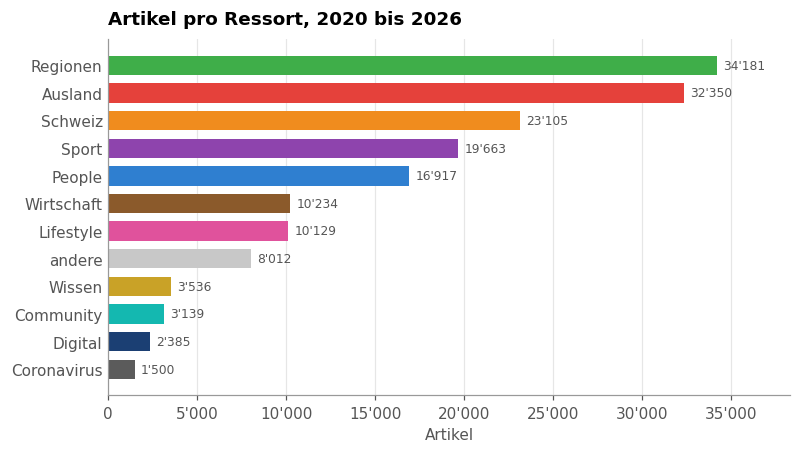

In [10]:
ressorts = artikel["hauptressort"].value_counts()

fig, ax = plt.subplots(figsize=(8, 4.2))
grafik.balken(ressorts, ax=ax, farbe=grafik.RESSORT_FARBEN, titel="Artikel pro Ressort, 2020 bis 2026", xlabel="Artikel")
grafik.tausender(ax, "x")
plt.show()

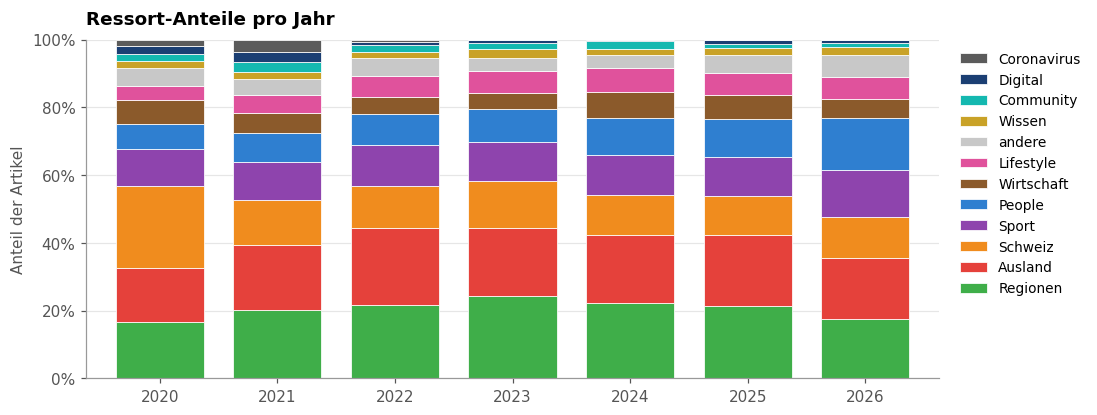

hauptressort,Regionen,Ausland,Schweiz,Sport,People,Wirtschaft,Lifestyle,andere,Wissen,Community,Digital,Coronavirus
jahr,,,,,,,,,,,,
2020,16.7,15.7,24.2,11.1,7.2,7.2,4.2,5.2,2.1,2.1,2.5,1.9
2021,20.3,19.2,13.2,11.3,8.6,6.0,5.2,4.7,2.1,2.8,2.9,3.8
2022,21.5,22.9,12.2,12.3,9.2,4.8,6.2,5.4,1.9,1.9,0.9,0.8
2023,24.4,20.0,13.8,11.5,9.6,5.0,6.5,3.7,2.5,1.9,1.0,0.0
2024,22.3,20.0,11.9,11.8,10.9,7.4,7.3,3.7,1.9,2.2,0.4,0.0
2025,21.4,20.9,11.5,11.7,11.0,7.0,6.7,5.2,2.1,1.1,1.4,0.0
2026,17.5,18.0,12.1,13.9,15.4,5.6,6.6,6.4,2.5,1.2,0.9,0.0


In [11]:
anteil = pd.crosstab(artikel["jahr"], artikel["hauptressort"], normalize="index")[ressorts.index]

fig, ax = plt.subplots(figsize=(10, 4))
anteil.plot.bar(stacked=True, ax=ax, width=0.75, edgecolor="white", linewidth=0.5,
                color=[grafik.RESSORT_FARBEN[r] for r in anteil.columns])
ax.set(title="Ressort-Anteile pro Jahr", xlabel="", ylabel="Anteil der Artikel")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="x", visible=False)
grafik.prozent(ax)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", reverse=True)
plt.show()

(anteil * 100).round(1)

Die drei grössten Ressorts sind wie erwartet Regionen, Ausland und Schweiz, allerdings mit Regionen vor der Schweiz. Zusammen
haben sie gut die Hälfte aller Artikel. Das Corona-Ressort gibt es nur 2020 bis 2022.

Über die Jahre verschieben sich die Anteile spürbar. Die Schweiz hat 2020 noch 24 %, danach nur noch 12 bis 14 %. People
wächst von 7 % auf 15 % im Jahr 2026. Ob dahinter eine andere Berichterstattung steckt oder eine neue Einteilung im CMS, können
wir aus den Daten nicht unterscheiden. Für H2 heisst das: Das Ressort ist ein redaktionelles Etikett, kein festes Merkmal eines
Themas. Die Ereignisseiten (zusammen knapp 5 %) fassen wir unter „andere“ zusammen. 2026 ist nur bis Anfang November enthalten.

## 6. Textlänge

Längere Texte liefern mehr Keyword-Kandidaten. Wenn ein Ressort viel längere Texte hat, könnte es das Themennetz
stärker prägen. Die Länge zeigt ausserdem, ob der Parser den Text vollständig liest: Viele Artikel mit 0 Wörtern
wären ein Warnsignal.

Wir erwarten typische Online-News mit 200 bis 400 Wörtern. Videos und Bildstrecken haben kaum Text.

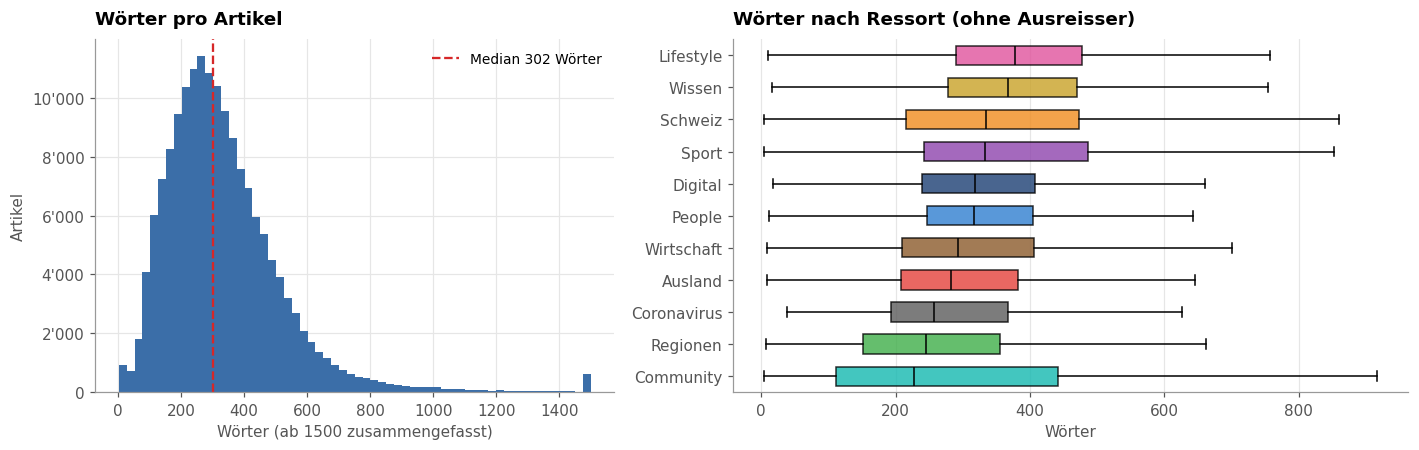

Artikel ohne Text: 0.6%
Artikel mit über 1500 Wörtern: 0.4%


In [12]:
mit_text = artikel[artikel["wortanzahl"] > 0]
median = mit_text["wortanzahl"].median()
reihenfolge = (mit_text[mit_text["hauptressort"] != "andere"]
               .groupby("hauptressort")["wortanzahl"].median().sort_values().index)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
axes[0].hist(mit_text["wortanzahl"].clip(upper=1500), bins=60, color=grafik.BLAU)
axes[0].axvline(median, color=grafik.AKZENT, linestyle="--", label=f"Median {median:.0f} Wörter")
axes[0].set(title="Wörter pro Artikel", xlabel="Wörter (ab 1500 zusammengefasst)", ylabel="Artikel")
axes[0].legend()
grafik.tausender(axes[0])

box = axes[1].boxplot([mit_text.loc[mit_text["hauptressort"] == r, "wortanzahl"] for r in reihenfolge],
                      orientation="horizontal", showfliers=False, patch_artist=True, widths=0.6,
                      medianprops={"color": "black"})
for teil, r in zip(box["boxes"], reihenfolge):
    teil.set(facecolor=grafik.RESSORT_FARBEN[r], alpha=0.8)
axes[1].set_yticks(range(1, len(reihenfolge) + 1), reihenfolge)
axes[1].set(title="Wörter nach Ressort (ohne Ausreisser)", xlabel="Wörter")
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print(f"Artikel ohne Text: {(artikel['wortanzahl'] == 0).mean():.1%}")
print(f"Artikel mit über 1500 Wörtern: {(artikel['wortanzahl'] > 1500).mean():.1%}")

Der typische Artikel hat rund 300 Wörter, die meisten liegen zwischen 150 und 500. Das entspricht unserer Erwartung. Nur 0,6 %
der Artikel haben keinen Text und 0,4 % mehr als 1'500 Wörter. Der Parser liest den Text also offenbar vollständig.

Zwischen den Ressorts sind die Unterschiede mässig: Regionen und Community schreiben am kürzesten (Median um 230 Wörter),
Lifestyle und Wissen am längsten (um 370). Weil die Keyword-Schicht pro Artikel höchstens 8 Keywords behält, zählt im
Themennetz jeder Artikel gleich viel, egal wie lang er ist.

## 7. Reaktionen: Ab wann gibt es Daten?

Likes, Shares und Kommentare sind unser Mass für die Resonanz beim Publikum. Beim Crawlen ist uns aufgefallen, dass
ältere Artikel fast nur Nullen haben. Bevor wir eine 0 als „kein Interesse“ lesen, müssen wir wissen, ab wann
20 Minuten die Reaktionen überhaupt zählt.

Wir vermuten einen klaren Bruch im Frühling 2020, als 20 Minuten auf ein neues System umgestellt hat.
Hier verwenden wir die Rohwerte der Quelle, ohne unsere Korrektur.

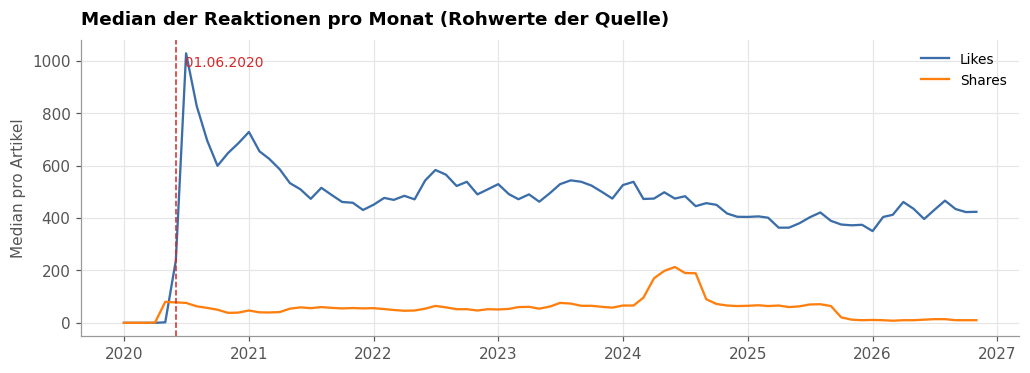

,Anteil mit likes > 0,Anteil mit shares > 0,Anteil mit kommentare > 0
monat,,,
2020-01,28%,14%,0%
2020-02,30%,16%,0%
2020-03,35%,25%,0%
2020-04,40%,52%,10%
2020-05,63%,99%,67%
2020-06,98%,100%,44%
2020-07,100%,99%,54%
2020-08,100%,99%,53%


In [13]:
verlauf = roh.groupby("monat")[["likes", "shares"]].median()
verlauf.index = pd.to_datetime(verlauf.index)
start = pd.Timestamp(daten.REAKTIONEN_AB)

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(verlauf.index, verlauf["likes"], label="Likes", color=grafik.BLAU)
ax.plot(verlauf.index, verlauf["shares"], label="Shares", color=grafik.PALETTE[1])
ax.axvline(start, color=grafik.AKZENT, linestyle="--", linewidth=1)
ax.text(start, verlauf.max().max() * 0.95, f"  {start:%d.%m.%Y}", color=grafik.AKZENT, fontsize=9)
ax.set(title="Median der Reaktionen pro Monat (Rohwerte der Quelle)", ylabel="Median pro Artikel")
ax.legend(loc="upper right")
plt.show()

anfang = roh[roh["monat"] < "2020-09"]
(anfang.groupby("monat")[["likes", "shares", "kommentare"]]
       .agg(lambda s: (s.fillna(0) > 0).mean())
       .map("{:.0%}".format)
       .rename(columns=lambda c: f"Anteil mit {c} > 0"))

Der Bruch ist sehr deutlich: Bis April 2020 liegt der Median bei 0, im Juni springt er auf über 1'000 Likes. Ganz leer sind die
frühen Monate aber nicht. Von Januar bis April 2020 hat etwa ein Drittel der Artikel mindestens ein Like. Vermutlich wurden ältere
Artikel nach der Umstellung noch vereinzelt gelikt. Ab Juni 2020 haben praktisch alle Artikel Likes. Wir behandeln deshalb alle
Reaktionen vor dem 1. Juni 2020 als fehlend.

Nicht erwartet haben wir die Schwankungen danach. Bei den Shares steigt der Median 2024 vorübergehend auf rund 200 und fällt ab
Herbst 2025 auf etwa 10. Das sieht nach einer Änderung in der Zählweise aus, nicht nach einem anderen Verhalten des Publikums.
Shares über die Jahre zu vergleichen, wäre deshalb irreführend. Auch die Likes sind 2020 und 2021 höher als später.

## 8. Wie sind die Reaktionen verteilt?

Reaktionen im Netz sind meistens sehr ungleich verteilt: Wenige Artikel bekommen sehr viel, die meisten wenig.
Davon hängt ab, ob wir in Notebook 03 mit Mittelwerten oder mit Medianen arbeiten.

Wir erwarten eine stark rechtsschiefe Verteilung mit einigen hundert Likes im typischen Fall und deutlich weniger
Shares und Kommentaren.

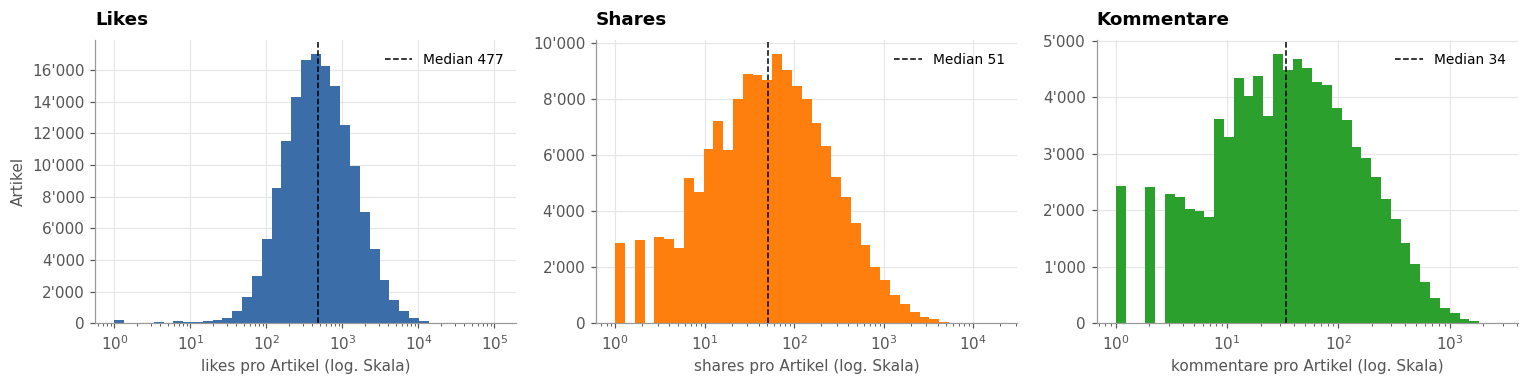

,median,mean,max
likes,476.0,825.0,109097.0
shares,49.0,152.0,19025.0
kommentare,32.0,84.0,2770.0


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=False)
for ax, spalte, farbe in zip(axes, daten.REAKTIONEN, [grafik.BLAU, grafik.PALETTE[1], grafik.PALETTE[2]]):
    werte = reaktiv[spalte].dropna().astype(float)
    werte = werte[werte > 0]
    ax.hist(werte, bins=np.logspace(0, np.log10(werte.max()), 40), color=farbe)
    ax.set_xscale("log")
    ax.axvline(werte.median(), color="black", linestyle="--", linewidth=1, label=f"Median {werte.median():.0f}")
    ax.set(title=spalte.capitalize(), xlabel=f"{spalte} pro Artikel (log. Skala)")
    ax.legend()
    grafik.tausender(ax)
axes[0].set_ylabel("Artikel")
plt.tight_layout()
plt.show()

reaktiv[daten.REAKTIONEN].astype(float).agg(["median", "mean", "max"]).T.round(0)

Die Verteilungen sind wie erwartet stark rechtsschief. Der Median liegt bei 476 Likes, 49 Shares und 32 Kommentaren, die
Mittelwerte sind fast doppelt bis dreimal so hoch, und einzelne Artikel erreichen über 100'000 Likes. Ein Mittelwert würde von
wenigen viralen Artikeln bestimmt. In Notebook 03 arbeiten wir deshalb mit Medianen, Rangkorrelationen und logarithmischen Achsen.

## 9. Wo darf kommentiert werden?

Bei vielen Artikeln fehlt die Kommentarzahl ganz. Die Seite zeigt dann „0“, aber das Kommentarfeld ist gesperrt.
Wir wollen wissen, ob die Sperre nach einer gewissen Zeit automatisch kommt oder ob die Redaktion pro Thema entscheidet.
Im ersten Fall müssten ältere Jahre fast vollständig gesperrt sein.

Wir erwarten Sperren vor allem bei Unfällen, Verbrechen und Kriegen, also in den Ressorts Regionen und Ausland.

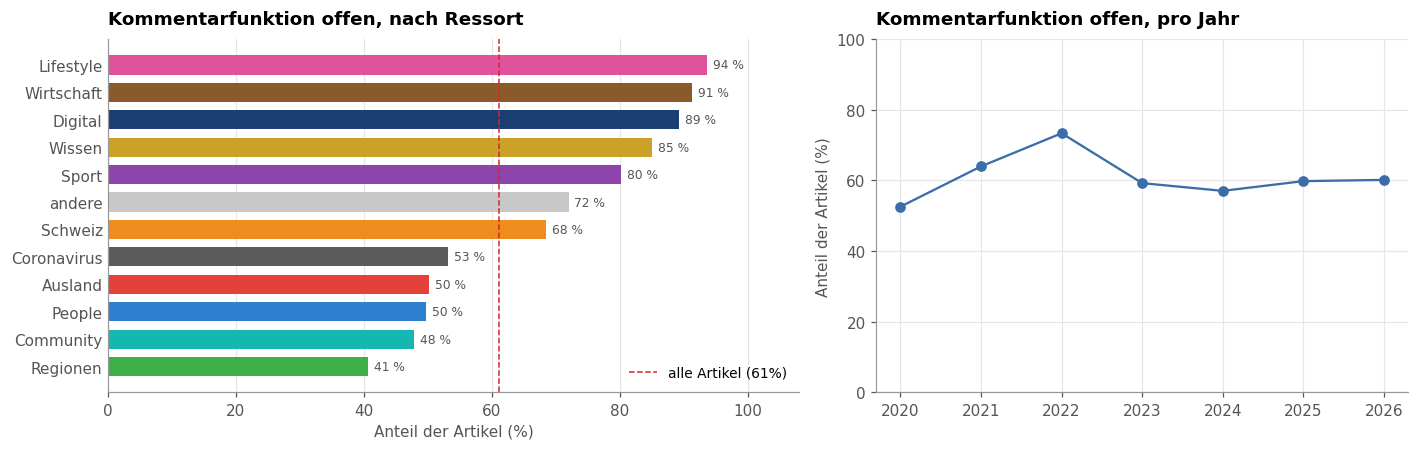

In [15]:
offen_ressort = reaktiv.groupby("hauptressort")["kommentare"].agg(lambda s: s.notna().mean()).sort_values(ascending=False)
offen_jahr = reaktiv.groupby("jahr")["kommentare"].agg(lambda s: s.notna().mean())
insgesamt = reaktiv["kommentare"].notna().mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
grafik.balken(offen_ressort * 100, ax=axes[0], farbe=grafik.RESSORT_FARBEN, fmt="{:.0f} %",
              referenz=insgesamt * 100, referenz_label=f"alle Artikel ({insgesamt:.0%})",
              titel="Kommentarfunktion offen, nach Ressort", xlabel="Anteil der Artikel (%)")
axes[0].set_xlim(0, 108)
axes[1].plot(offen_jahr.index, offen_jahr.values * 100, marker="o", color=grafik.BLAU)
axes[1].set(title="Kommentarfunktion offen, pro Jahr", ylabel="Anteil der Artikel (%)", ylim=(0, 100))
plt.tight_layout()
plt.show()

In [16]:
# Dieselbe Frage für die Ereignisseiten mit mindestens 200 Artikeln
seiten = reaktiv.groupby("ressort_1")["kommentare"].agg(artikel="size", offen=lambda s: s.notna().mean())
seiten = seiten[(seiten["artikel"] >= 200) & ~seiten.index.isin(daten.HAUPTRESSORTS)].sort_values("offen")
seiten.assign(offen=seiten["offen"].map("{:.0%}".format))

,artikel,offen
ressort_1,,
Katastrophe in Crans-Montana,311,13%
Iran-Krieg,345,59%
unbekannt,2470,65%
Faktenchecks,202,75%
Kino & Streaming,597,76%
Good Vibes,262,85%
GOAT Radio,227,87%
Wetter,754,95%
#WIRSINDZUKUNFT,390,96%


Insgesamt ist die Kommentarfunktion bei 61 % der Artikel offen. Die Unterschiede zwischen den Ressorts sind gross: Lifestyle,
Wirtschaft und Digital sind fast immer offen (89 bis 94 %), Regionen nur zu 41 %. Ausland, People und Community liegen um 50 %.
Bei Regionen und Ausland hatten wir das erwartet, bei People nicht.

Pro Jahr schwankt der Anteil zwischen 52 und 73 %, ohne dass ältere Jahre stärker gesperrt wären. Eine automatische Sperre nach
einer gewissen Zeit können wir damit ausschliessen. Es ist eine Entscheidung pro Artikel, die stark vom Thema abhängt. Am
deutlichsten zeigt das die Ereignisseite zur Katastrophe in Crans-Montana mit nur 13 % offenen Artikeln. Kommentarzahlen
vergleichen wir deshalb nur bei offenen Artikeln, und die Sperrquote werten wir in Notebook 03 als eigenen Befund aus.

## 10. Hängen die Reaktionen zusammen?

Messen Likes, Shares und Kommentare dasselbe, nämlich Aufmerksamkeit, oder verschiedene Dinge wie Zustimmung,
Weiterempfehlung und Diskussion? Wenn sie nur mässig zusammenhängen, lohnt es sich, sie in Notebook 03 getrennt
auszuwerten. Ausserdem liefert die Seite ein Feld `views`, das nirgends angezeigt wird. Wir prüfen, ob es Seitenaufrufe sein können.

Wir erwarten positive, aber nicht perfekte Zusammenhänge. Wenn `views` Seitenaufrufe sind, muss der Wert weit über
den Likes liegen.

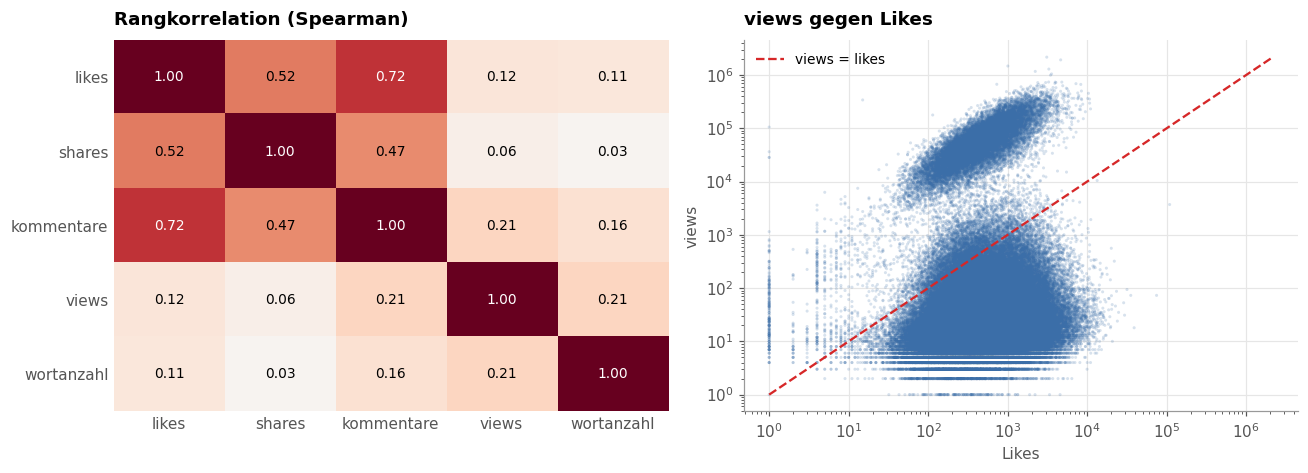

Artikel mit weniger views als Likes: 84%


In [17]:
korrelation = reaktiv[["likes", "shares", "kommentare", "views", "wortanzahl"]].astype(float).corr(method="spearman")
mit_views = reaktiv[(reaktiv["views"] > 0) & (reaktiv["likes"] > 0)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1, 1]})
grafik.heatmap(korrelation, ax=axes[0], cmap="RdBu_r", fmt="{:.2f}", schrift=9, titel="Rangkorrelation (Spearman)")
axes[0].get_images()[0].set_clim(-1, 1)
axes[1].scatter(mit_views["likes"], mit_views["views"], s=4, alpha=0.2, color=grafik.BLAU, edgecolors="none")
grenze = [1, float(max(mit_views["likes"].max(), mit_views["views"].max()))]
axes[1].plot(grenze, grenze, color=grafik.AKZENT, linestyle="--", label="views = likes")
axes[1].set(xscale="log", yscale="log", title="views gegen Likes", xlabel="Likes", ylabel="views")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Artikel mit weniger views als Likes: {(reaktiv['views'] < reaktiv['likes']).mean():.0%}")

Likes und Kommentare hängen am stärksten zusammen (ρ = 0,72), Shares mit beiden nur mässig (0,52 und 0,47). Die drei Masse
messen also nicht genau dasselbe. Shares verhalten sich am eigenständigsten. Mit der Wortanzahl hängen die Reaktionen kaum zusammen.

In der Streugrafik fallen zwei getrennte Punktwolken auf. Wir schauen deshalb, aus welcher Zeit die Artikel der oberen Wolke
stammen (mehr als fünfmal so viele views wie Likes).

In [18]:
obere_wolke = reaktiv["views"] > 5 * reaktiv["likes"]
anteil = obere_wolke.groupby(reaktiv["monat"]).mean()
anteil.loc["2025-09":].map("{:.0%}".format).to_frame("Anteil obere Wolke").T

monat,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10,2026-11
Anteil obere Wolke,2%,3%,4%,4%,13%,70%,100%,100%,100%,100%,100%,100%,100%,100%,100%


Die Tabelle erklärt die zwei Wolken: Bis Ende 2025 liegen fast alle Artikel in der unteren Wolke, ab Februar/März 2026 fast alle
in der oberen. Vermutlich zählt 20 Minuten die Aufrufe erst seit Anfang 2026. Ältere Artikel haben nur die Aufrufe gesammelt, die
seither noch dazugekommen sind. Für die Jahre 2020 bis 2025 ist `views` damit nicht brauchbar. Wir verwenden das Feld nicht.

## 11. Werden Artikel nachträglich geändert?

Artikel werden nach der Publikation ergänzt und korrigiert. Wir sehen nur die letzte Fassung. Wenn sich dabei der
Titel ändert, ändern sich auch die Keywords aus dem Titel. Wir wollen abschätzen, wie viele Artikel das betrifft.

Wir erwarten, dass viele Artikel innerhalb weniger Stunden aktualisiert werden (Nachträge bei laufenden Ereignissen).

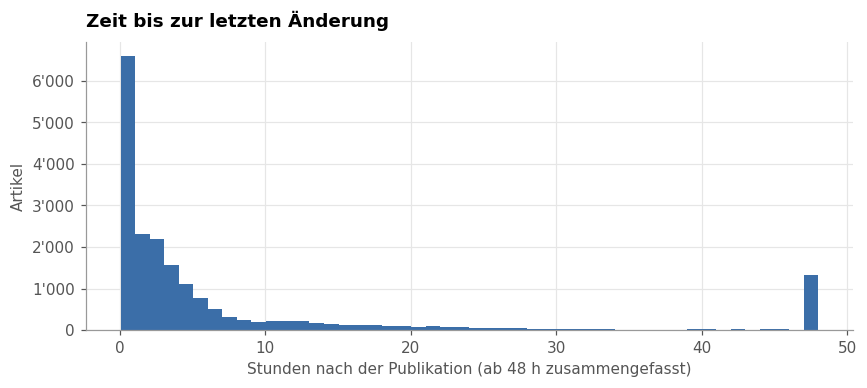

Nach der Publikation geändert: 12% der Artikel
Median: 2.4 Stunden nach der Publikation
Erst nach mehr als einer Woche: 3.9% der geänderten Artikel


In [19]:
verzug = (artikel["aktualisiert"] - artikel["datum"]).dt.total_seconds() / 3600
geaendert = verzug[verzug > 0.05]  # mehr als 3 Minuten nach der Publikation

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(geaendert.clip(upper=48), bins=48, color=grafik.BLAU)
ax.set(title="Zeit bis zur letzten Änderung", xlabel="Stunden nach der Publikation (ab 48 h zusammengefasst)", ylabel="Artikel")
grafik.tausender(ax)
plt.show()

print(f"Nach der Publikation geändert: {len(geaendert) / len(artikel):.0%} der Artikel")
print(f"Median: {geaendert.median():.1f} Stunden nach der Publikation")
print(f"Erst nach mehr als einer Woche: {(geaendert > 24 * 7).mean():.1%} der geänderten Artikel")

Hier lagen wir falsch: Nur 12 % der Artikel wurden nach der Publikation geändert, und wenn, dann meistens innerhalb weniger
Stunden (Median 2,4 Stunden). Sehr späte Änderungen sind selten. Die Fassung, die wir analysieren, entspricht also bei fast allen
Artikeln der ursprünglichen. Wir wissen allerdings nicht, ob die Seite jede Änderung im Feld `aktualisiert` festhält.

## 12. Autorinnen und Autoren

Für das Redaktionsnetz in Notebook 03 brauchen wir pro Artikel die richtigen Personen. Je nach Zeitraum liefert die
Seite volle Namen mit einer ID, nur ein Kürzel oder eine Ortsangabe. `data_extraction.autoren` führt das zu Personen
zusammen. Hier prüfen wir, wie gut das gelingt.

Wir erwarten 2020 fast nur Kürzel und ab 2021 volle Namen. Einige alte Kürzel lassen sich wahrscheinlich keiner Person zuordnen.

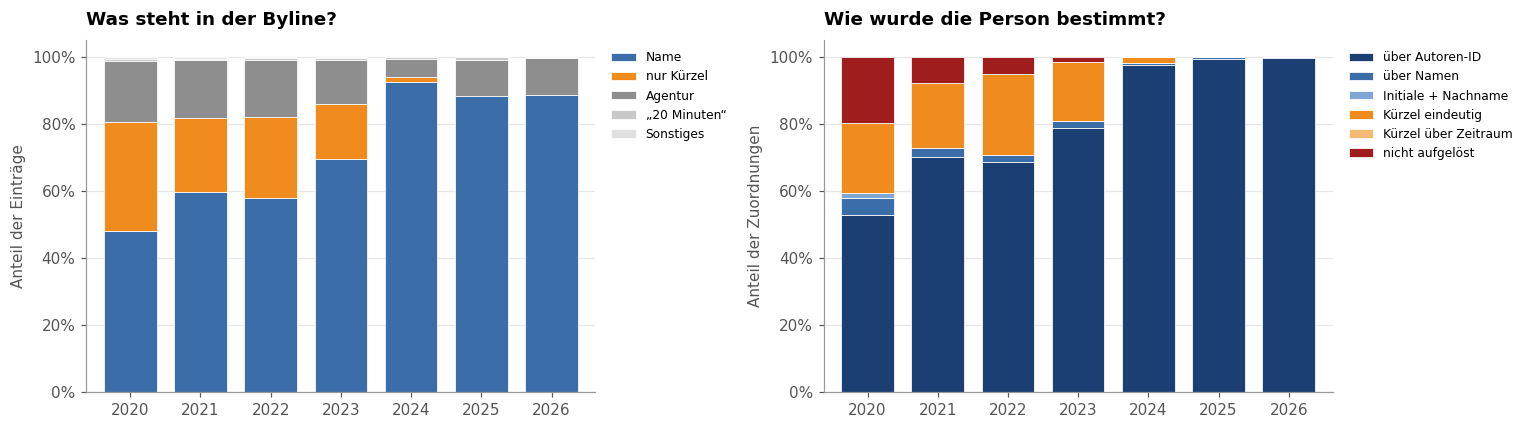

Personen: 1,149
Anteil Zuordnungen, die nur ein Kürzel geblieben sind:
jahr
2020    19.7%
2021     7.6%
2022     5.2%
2023     1.5%
2024     0.1%
2025     0.0%
2026     0.0%


In [20]:
BYLINE = {"person": "Name", "kuerzel": "nur Kürzel", "agentur": "Agentur", "20min": "„20 Minuten“", "sonstige": "Sonstiges"}
METHODE = {"id": "über Autoren-ID", "name": "über Namen", "initiale": "Initiale + Nachname",
           "kuerzel": "Kürzel eindeutig", "kuerzel_zeit": "Kürzel über Zeitraum",
           "mehrdeutig": "Kürzel mehrdeutig", "ungeloest": "nicht aufgelöst"}
BYLINE_FARBEN = dict(zip(BYLINE.values(), ["#3b6ea8", "#f08c1e", "#8e8e8e", "#c8c8c8", "#e0e0e0"]))
# Blau-Töne = sicher bestimmt, Orange = über Kürzel, Rot = unsicher
METHODE_FARBEN = dict(zip(METHODE.values(), ["#1b3f73", "#3b6ea8", "#7fa6d4", "#f08c1e", "#f5b971", "#e5413b", "#a01d1d"]))

mit_jahr = autoren_roh.merge(artikel[["url", "jahr"]], on="url")
autoren = personen[personen["rolle"] == "autor"].merge(artikel[["url", "jahr"]], on="url")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
art = pd.crosstab(mit_jahr["jahr"], mit_jahr["art"].map(BYLINE), normalize="index")
art = art[[s for s in BYLINE.values() if s in art]]
art.plot.bar(stacked=True, ax=axes[0], width=0.75, edgecolor="white", linewidth=0.5,
             color=[BYLINE_FARBEN[s] for s in art.columns])
axes[0].set(title="Was steht in der Byline?", xlabel="", ylabel="Anteil der Einträge")
methode = pd.crosstab(autoren["jahr"], autoren["methode"].map(METHODE), normalize="index")
methode = methode[[s for s in METHODE.values() if s in methode]]
methode.plot.bar(stacked=True, ax=axes[1], width=0.75, edgecolor="white", linewidth=0.5,
                 color=[METHODE_FARBEN[s] for s in methode.columns])
axes[1].set(title="Wie wurde die Person bestimmt?", xlabel="", ylabel="Anteil der Zuordnungen")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="x", visible=False)
    grafik.prozent(ax)
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

print(f"Personen: {autoren['person'].nunique():,}")
print("Anteil Zuordnungen, die nur ein Kürzel geblieben sind:")
print((1 - autoren.groupby("jahr")["aufgeloest"].mean()).map("{:.1%}".format).to_string())

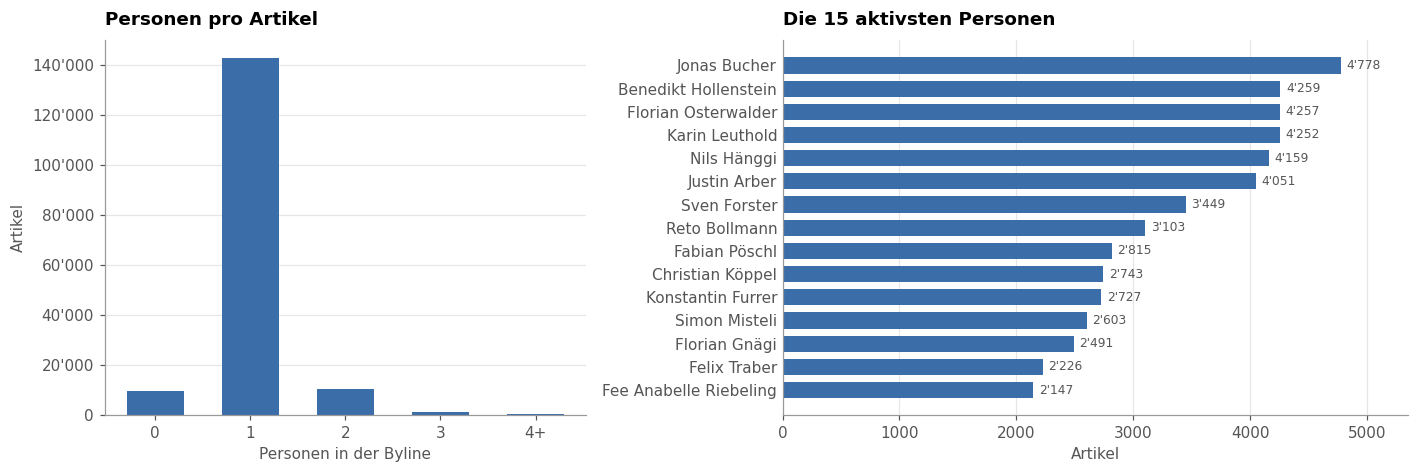

Ohne Person (nur Agentur oder Redaktion): 5.9%
Anteil der Artikel die durch eine Person verfasst wurden: 86.6%
Mit mindestens zwei Personen: 7.5%


In [21]:
pro_artikel = autoren.groupby("url").size().reindex(artikel["url"], fill_value=0)
verteilung = pro_artikel.clip(upper=4).value_counts().sort_index()
verteilung.index = ["0", "1", "2", "3", "4+"][: len(verteilung)]
aktivste = autoren["person"].value_counts().head(15)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.3]})
axes[0].bar(verteilung.index, verteilung.values, color=grafik.BLAU, width=0.6)
axes[0].set(title="Personen pro Artikel", xlabel="Personen in der Byline", ylabel="Artikel")
axes[0].grid(axis="x", visible=False)
grafik.tausender(axes[0])
grafik.balken(aktivste, ax=axes[1], titel="Die 15 aktivsten Personen", xlabel="Artikel",
              farbe=[grafik.GRAU if p.startswith("kürzel:") else grafik.BLAU for p in aktivste.index[::-1]])
plt.tight_layout()
plt.show()

print(f"Ohne Person (nur Agentur oder Redaktion): {(pro_artikel == 0).mean():.1%}")
print(f"Anteil der Artikel die durch eine Person verfasst wurden: {(pro_artikel == 1).mean():.1%}")
print(f"Mit mindestens zwei Personen: {(pro_artikel >= 2).mean():.1%}")

Die Erwartung bestätigt sich. 2020 steht bei rund einem Drittel der Bylines nur ein Kürzel, ab 2024 fast nur noch volle Namen.
Die meisten Personen erkennen wir über die Autoren-ID. Für viele Kürzel findet `autoren.py` die Person über einen Artikel, in dem
Name und Kürzel gemeinsam vorkommen. Unaufgelöst bleiben 2020 knapp 20 % der Zuordnungen, 2021 noch 8 % und ab 2023 fast keine.
Diese Kürzel bleiben als eigene Knoten (`kürzel:xyz`) im Netz. Eine Person kann deshalb 2020 doppelt vorkommen, als Name und als
Kürzel. Bei Aussagen über einzelne Personen in diesem Jahr müssen wir vorsichtig sein.

Für das Co-Autorennetz ist die zweite Grafik entscheidend: Nur 7,5 % der Artikel haben zwei oder mehr Personen. Das Netz beruht
also auf rund 12'000 Artikeln. Die meisten Artikel werden von einer Person allein gezeichnet.

## 13. Agenturmeldungen

Ein Teil der Artikel beruht auf Meldungen von Nachrichtenagenturen (SDA, dpa, AFP usw.). Solche Texte erscheinen bei vielen
Medien fast gleich. Für die Analyse ist das wichtig, weil Agenturtexte vor allem die Auslandsthemen prägen dürften.

Wir erwarten Agenturen vor allem im Ressort Ausland und einen eher sinkenden Anteil über die Jahre.

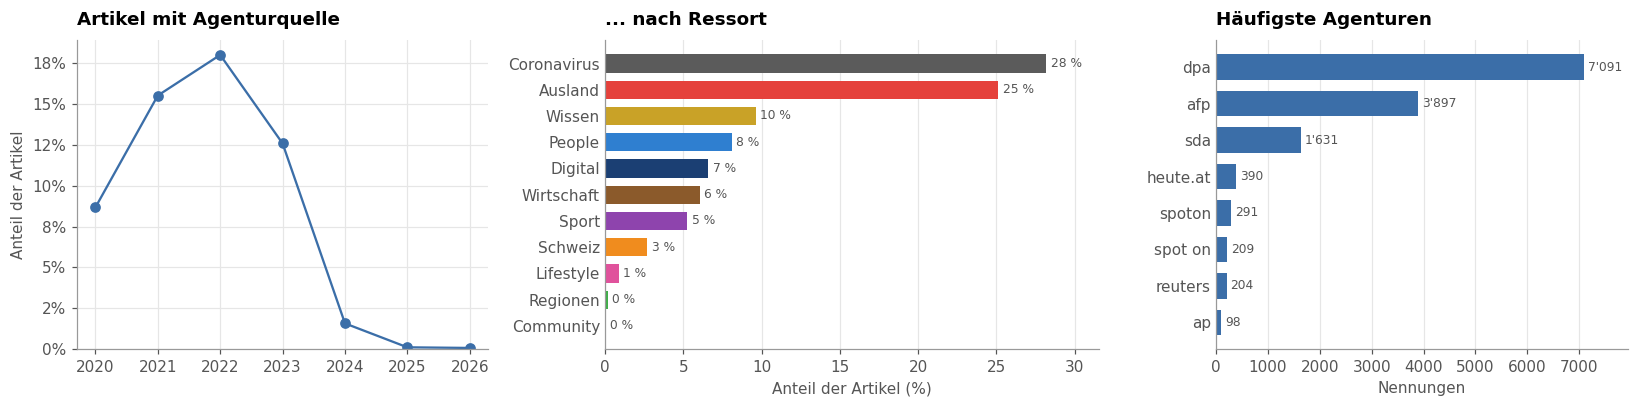

In [22]:
agentur = quellen_roh[quellen_roh["art"] == "agentur"]
artikel["mit_agentur"] = artikel["url"].isin(agentur["url"])
pro_jahr = artikel.groupby("jahr")["mit_agentur"].mean()
pro_ressort = (artikel[artikel["hauptressort"] != "andere"]
               .groupby("hauptressort")["mit_agentur"].mean().sort_values(ascending=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1, 1.2, 1]})
axes[0].plot(pro_jahr.index, pro_jahr.values, marker="o", color=grafik.BLAU)
axes[0].set(title="Artikel mit Agenturquelle", ylim=(0, None), ylabel="Anteil der Artikel")
grafik.prozent(axes[0])
grafik.balken(pro_ressort * 100, ax=axes[1], farbe=grafik.RESSORT_FARBEN, fmt="{:.0f} %",
              titel="... nach Ressort", xlabel="Anteil der Artikel (%)")
grafik.balken(agentur["kuerzel"].value_counts().head(8), ax=axes[2], titel="Häufigste Agenturen", xlabel="Nennungen")
plt.tight_layout()
plt.show()

Wie erwartet stammen Agenturtexte vor allem aus Ausland (25 %) und dem Corona-Ressort (28 %). Die häufigsten Agenturen sind dpa,
AFP und SDA. „spoton“ und „spot on“ sind dieselbe Agentur in zwei Schreibweisen.

Der Verlauf über die Jahre ist aber kein echter Rückgang. Ab 2024 fehlt die Quellenzeile fast immer (Abschnitt 4), gleichzeitig
steht die Agentur 2025 und 2026 bei rund 10 % der Bylines direkt im Autorenfeld (Abschnitt 12). Die Agentur ist also nur an eine
andere Stelle gewandert. Für eine Auswertung über die Jahre müssten wir beide Felder zusammennehmen.

## 14. Keywords

Die Keywords sind die Knoten des Themennetzes. Hier prüfen wir, ob sie inhaltlich sinnvoll sind (keine Füllwörter),
wie sie verteilt sind und ob sie bekannte Ereignisse zur richtigen Zeit zeigen. Wenn zum Beispiel „Coronavirus“ nicht
2020 und 2021 oben steht, stimmt mit der Methode etwas nicht.

Wir erwarten wenige sehr häufige Begriffe (Schweiz, Polizei) und sehr viele seltene. Corona sollte 2020/21 klar
sichtbar sein, die Ukraine ab 2022.

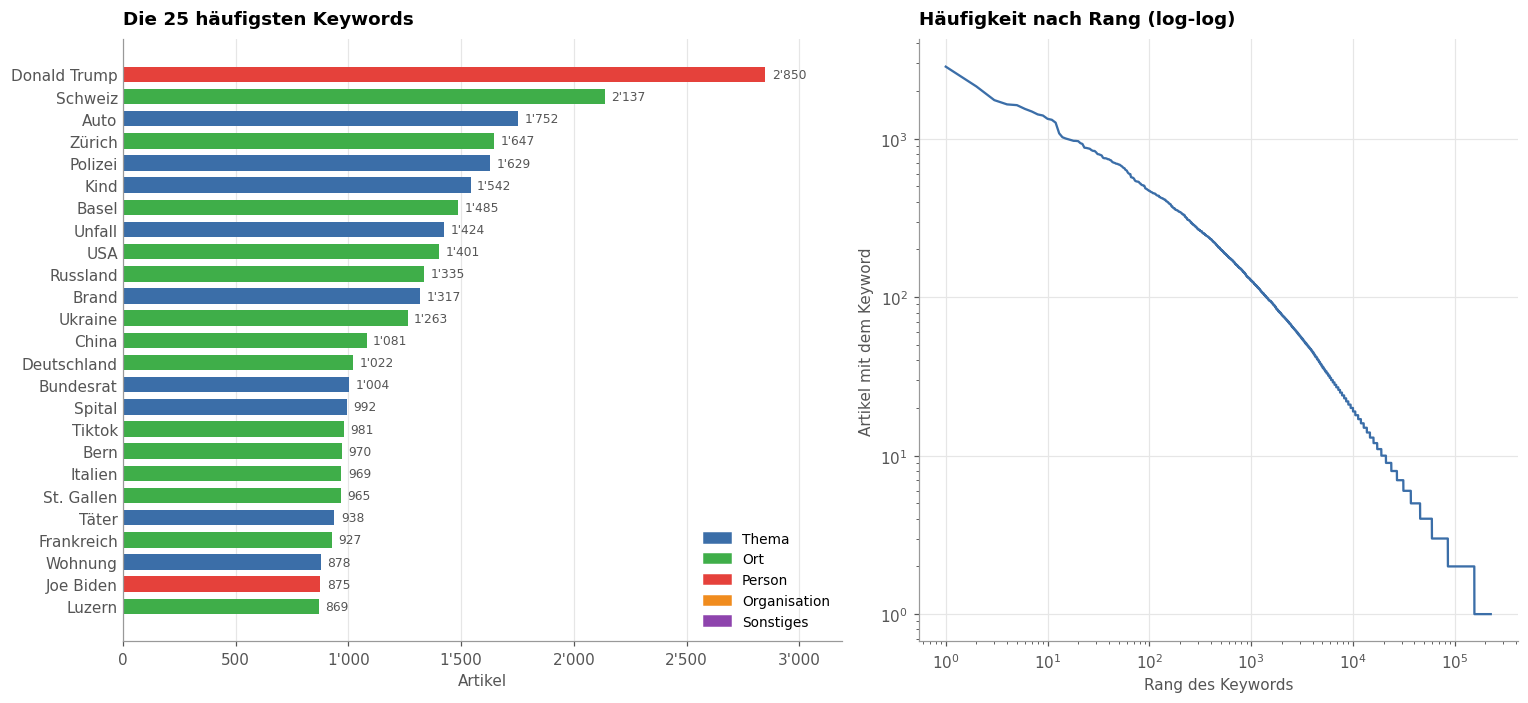

Verschiedene Keywords: 225,252
Keywords pro Artikel (Median): 8
Keywords in höchstens 5 Artikeln: 84%
Typen: Thema 44%, Ort 20%, Person 18%, Organisation 11%, Sonstiges 6%


In [23]:
TYPEN = {"THEMA": "Thema", "LOC": "Ort", "PER": "Person", "ORG": "Organisation", "MISC": "Sonstiges"}
haeufig = keywords["keyword"].value_counts()
typ_von = keywords.drop_duplicates("keyword").set_index("keyword")["typ"]
top25 = haeufig.head(25)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1.2, 1]})
grafik.balken(top25, ax=axes[0], titel="Die 25 häufigsten Keywords", xlabel="Artikel",
              farbe=[grafik.TYP_FARBEN[typ_von[k]] for k in top25.index[::-1]])
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=f) for f in grafik.TYP_FARBEN.values()],
               labels=list(TYPEN.values()), loc="lower right")
grafik.tausender(axes[0], "x")
axes[1].loglog(range(1, len(haeufig) + 1), haeufig.values, color=grafik.BLAU)
axes[1].set(title="Häufigkeit nach Rang (log-log)", xlabel="Rang des Keywords", ylabel="Artikel mit dem Keyword")
plt.tight_layout()
plt.show()

print(f"Verschiedene Keywords: {len(haeufig):,}")
print(f"Keywords pro Artikel (Median): {keywords.groupby('url').size().median():.0f}")
print(f"Keywords in höchstens 5 Artikeln: {(haeufig <= 5).mean():.0%}")
print("Typen:", ", ".join(f"{TYPEN[t]} {a:.0%}" for t, a in keywords["typ"].value_counts(normalize=True).items()))

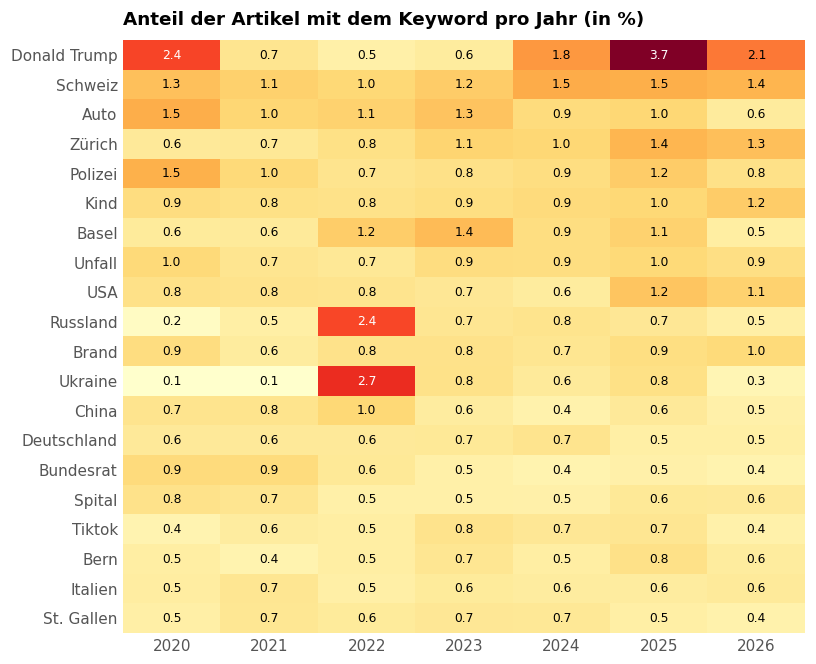

In [24]:
mit_jahr = keywords.merge(artikel[["url", "jahr"]], on="url")
n_jahr = artikel.groupby("jahr").size()
verlauf = pd.crosstab(mit_jahr["keyword"], mit_jahr["jahr"]).loc[haeufig.head(20).index] / n_jahr * 100

fig, ax = plt.subplots(figsize=(8, 7))
grafik.heatmap(verlauf, ax=ax, fmt="{:.1f}", cmap="YlOrRd", titel="Anteil der Artikel mit dem Keyword pro Jahr (in %)")
plt.show()

Die Verteilung hat wie erwartet einen langen Schwanz: 225'000 verschiedene Keywords, von denen 84 % in höchstens fünf Artikeln
vorkommen. Im Netz filtern wir sie mit `MIN_DF` weg. Ganz oben stehen Donald Trump, die Schweiz, Auto, Zürich und Polizei.

Der Zeitverlauf zeigt die bekannten Ereignisse: Russland und Ukraine springen 2022 nach oben, Donald Trump ist in den Wahl- und
Amtsjahren 2020, 2024 und 2025 am stärksten.

Eine Überraschung ist, dass Corona fehlt. Das Thema ist auf viele Varianten verteilt: „Corona“ (673 Artikel), „Coronavirus“ (598),
„Corona-Pandemie“, „Corona-Krise“, „Covid-19“. Dazu kommen Typfehler von spaCy („Corona“ als Person, „Covid-19“ als Ort) und
falsche Grundformen („Corona-Massnahma“). Im Netz erscheint Corona deshalb als mehrere kleinere Knoten statt als ein grosser.
Das schwächt die Prüfung von H1 für 2020, und wir müssen es dort erwähnen. Besser wäre eine Liste, die solche Varianten zusammenführt.

## 15. Stichprobe zur Plausibilitätsprüfung

Ob der Crawler richtig liest, lässt sich nur am Original prüfen. Wir ziehen deshalb 40 zufällige Artikel und vergleichen
sie von Hand mit der Seite auf 20min.ch: Titel, Datum, Autorinnen und Autoren sowie die Reaktionen.

Titel, Datum und Personen sollten stimmen. Bei den Reaktionen erwarten wir kleine Abweichungen, weil sie nach dem Crawl
weiter steigen.

Die Datei wird nur beim ersten Lauf geschrieben, damit die eingetragenen Prüfergebnisse nicht überschrieben werden.

In [25]:
ziel = daten.ROOT / "data" / "plausibilitaet_stichprobe.csv"
if ziel.exists():
    stichprobe = pd.read_csv(ziel)
    print(f"Vorhandene Stichprobe gelesen: {ziel}")
else:
    autor_liste = autoren.groupby("url")["person"].agg(" / ".join)
    stichprobe = roh.sample(40, random_state=2026)[
        ["url", "datum", "titel", "ressort_pfad", "likes", "shares", "kommentare", "wortanzahl", "format"]
    ].assign(autoren=lambda d: d["url"].map(autor_liste), titel_ok="", datum_ok="", autoren_ok="", reaktionen_ok="")
    stichprobe.to_csv(ziel, index=False, encoding="utf-8-sig")
    print(f"Neue Stichprobe gespeichert: {ziel} (in Excel öffnen, Spalten *_ok mit ja/nein füllen)")

geprueft = [s for s in ["titel_ok", "datum_ok", "autoren_ok", "reaktionen_ok"] if stichprobe[s].notna().any()]
if geprueft:
    print("Anteil korrekt:")
    print(stichprobe[geprueft].apply(lambda s: s.astype(str).str.lower().eq("ja").mean()).map("{:.0%}".format).to_string())
stichprobe.head(5)

Vorhandene Stichprobe gelesen: C:\Users\elias\Desktop\FHNW\SAN\SAN_20_Minuten\data\plausibilitaet_stichprobe.csv


,url,datum,titel,ressort_pfad,likes,shares,kommentare,wortanzahl,format,autoren,titel_ok,datum_ok,autoren_ok,reaktionen_ok
0,https://www.20min.ch/story/86-prozent-der-infizierten-wissen-nichts-davon-304753555863,2020-03-18 18:16:00+00:00,Die meisten Infizierten wissen nichts davon,Gesundheit,0.0,2.0,NaN,428.0,artikel,Jean-Claude Gerber,NaN,NaN,NaN,NaN
1,https://www.20min.ch/story/sommerhaus-der-stars-lina-baumann-ryan-woehrl-trennung-fremdgehen-soc...,2026-06-09 09:09:05.952000+00:00,Nach Fremdgehvorwürfen: «Sommerhaus der Stars»-Paar Lina Baumann und Ryan Wöhrl trennt sich,People,589.0,3.0,45.0,237.0,artikel,Janelle Oldani,NaN,NaN,NaN,NaN
2,https://www.20min.ch/story/eure-meinung-migros-hat-in-den-letzten-wochen-viel-verspielt-103043421,2024-02-15 16:49:40.061000+00:00,«Migros hat in den letzten Wochen viel verspielt»,Community,951.0,30.0,61.0,419.0,artikel,Deborah Gonzalez,NaN,NaN,NaN,NaN
3,https://www.20min.ch/story/cham-zg-in-baustellensignalisation-geprallt-lenker-entfernt-sich-uner...,2024-12-20 07:22:24.940000+00:00,Cham: Ein Auto ist in die Baustellensignalisation geprallt.,Regionen > Zentralschweiz,188.0,43.0,NaN,181.0,artikel,Cédric Bähler,NaN,NaN,NaN,NaN
4,https://www.20min.ch/story/joggerin-gefilmt-voyeur-kam-straffrei-davon-diese-petition-soll-das-n...,2025-08-25 17:32:50.781000+00:00,Petition fordert Gesetzesänderung: Voyeurismus soll auch ohne Nacktheit strafbar werden,Ausland,795.0,29.0,101.0,348.0,artikel,Benedikt Hollenstein,NaN,NaN,NaN,NaN


*Die Stichprobe ist gezogen, die Prüfung von Hand steht noch aus. Nach dem Ausfüllen der Spalten `*_ok` hier festhalten, welcher
Anteil pro Feld stimmt und welche Art von Abweichungen vorkommt.*

## 16. Vergleich mit der alten Extraktion

Am Anfang des Projekts hatten wir einen anderen Datensatz (`20min_metadaten_keywords_clean.csv`). Den Crawler haben wir neu
gebaut, weil uns dort Fehler aufgefallen sind. Hier vergleichen wir beide Versionen für die gemeinsamen Artikel.

Wir erwarten bei den meisten Artikeln dieselben Reaktionswerte. Bei einem Teil waren die alten Werte zehnmal zu hoch.
Die neuen Keywords sollten ganze Namen und Grundformen sein statt einzelner Wortteile.

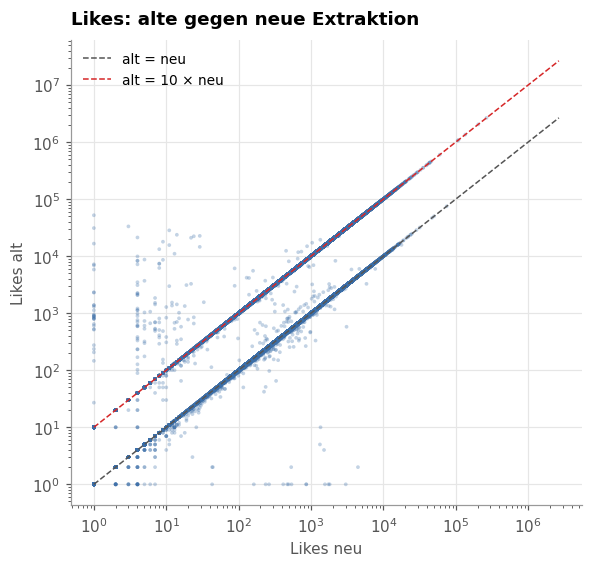

Gemeinsame Artikel: 137,298


,gleich,alt zehnfach
likes,53.4%,36.8%
shares,56.6%,37.9%
kommentare,42.7%,48.9%


,Keywords alt,Keywords neu
68865,"[""mandelmutter"", ""videos"", ""social"", ""essverhalten"", ""media""]","Mandelmutter, Essverhalten, Yolanda, Mutter, Jugend, Mandel, US-Reality-Show, The Real Housewive..."
43688,"[""österreich"", ""demo"", ""tomsits"", ""corona"", ""stimmung""]","Österreich, Massnahmenkritik, Wut, Wien, Regierung, Stimmung, Grossdemo, Gegendemonstration"
120175,"[""bagger"", ""fajauna"", ""lehrling"", ""eingeklemmt"", ""forstarbeiterlehrling""]","Fajauna, S-chanf, Lehrling, Baggerunfall, Bagger, Arbeitsunfall, Rettungsdienst Schier, Samedan"
42106,"[""kleeblatt"", ""ricardo"", ""mio"", ""versehen"", ""community""]","Kleeblatt, Spasskäufer, Ricardo, Mojca Fuks, Resonanz, TX Group, Grundstück, Thurgauer"
52152,"[""oscar"", ""smith"", ""verbot"", ""akademie"", ""eklat""]","Smith, Ohrfeigen-Eklat, Oscar-Zeremonie, Ohrfeige, Oscar-Akademie, Hollywood-Star Will Smith, Ba..."


In [26]:
alt_pfad = daten.ROOT / "data" / "20min_metadaten_keywords_clean.csv"
if alt_pfad.exists():
    alt = pd.read_csv(alt_pfad, usecols=["url", "likes", "shares", "kommentare", "keywords"])
    vergleich = roh[["url", "likes", "shares", "kommentare"]].merge(alt, on="url", suffixes=("_neu", "_alt"))
    beide = vergleich[(vergleich["likes_alt"] > 0) & (vergleich["likes_neu"] > 0)]

    fig, ax = plt.subplots(figsize=(6, 5.5))
    ax.scatter(beide["likes_neu"].astype(float), beide["likes_alt"], s=6, alpha=0.3, color=grafik.BLAU, edgecolors="none")
    grenze = np.array([1, float(max(beide["likes_neu"].max(), beide["likes_alt"].max()))])
    ax.plot(grenze, grenze, "--", color=grafik.DUNKELGRAU, linewidth=1, label="alt = neu")
    ax.plot(grenze, grenze * 10, "--", color=grafik.AKZENT, linewidth=1, label="alt = 10 × neu")
    ax.set(xscale="log", yscale="log", xlabel="Likes neu", ylabel="Likes alt", title="Likes: alte gegen neue Extraktion")
    ax.legend()
    plt.show()

    print(f"Gemeinsame Artikel: {len(vergleich):,}")
    zeilen = {}
    for spalte in daten.REAKTIONEN:
        a, n = vergleich[f"{spalte}_alt"], vergleich[f"{spalte}_neu"].astype(float)
        zeilen[spalte] = {"gleich": ((a == n) | (a.isna() & n.isna())).mean(),
                          "alt zehnfach": ((a == n * 10) & (n > 0)).mean()}
    display(pd.DataFrame(zeilen).T.map("{:.1%}".format))

    beispiel = vergleich.merge(keywords.groupby("url")["keyword"].agg(", ".join), on="url").sample(5, random_state=1)
    display(beispiel[["keywords", "keyword"]].rename(columns={"keywords": "Keywords alt", "keyword": "Keywords neu"}))
else:
    print("Die alte CSV liegt nicht im Ordner data/.")

Der Fehler im alten Datensatz war grösser als gedacht. Nur gut die Hälfte der Likes und Shares stimmt überein, und bei 37 bis 38 %
der Artikel ist der alte Wert genau zehnmal so hoch wie der neue, bei den Kommentaren sogar bei 49 %. Wir hatten mit etwa 10 %
gerechnet. In der Grafik liegen diese Artikel auf der roten Linie. Mit den alten Daten wären alle Aussagen über Reaktionen verzerrt
gewesen.

Bei den Keywords sieht man den Unterschied direkt: Früher waren es kleingeschriebene Einzelwörter („oscar“, „smith“), jetzt sind es
ganze Namen und zusammengesetzte Begriffe („Hollywood-Star Will Smith“, „Oscar-Zeremonie“). Im alten Netz wäre dieselbe Person
auf mehrere Knoten verteilt gewesen. Ganz fehlerfrei sind die neuen Keywords aber auch nicht, wie das Corona-Beispiel in Abschnitt 14 zeigt.

## Was wir aus der EDA mitnehmen

| Befund | Umgang damit | umgesetzt in |
|---|---|---|
| Reaktionen werden erst ab Juni 2020 gezählt | vorher als fehlend behandeln, Reaktionsanalysen ab Juni 2020 | `daten.REAKTIONEN_AB` |
| Kommentarfunktion wird pro Artikel gesperrt | fehlend statt 0, Sperrquote als eigener Befund | `daten.py`, Notebook 03 |
| `views` zählt erst seit Anfang 2026 | nicht verwenden | – |
| Zählweise der Shares ändert sich 2024 und 2025 | Shares nicht über die Jahre vergleichen | Notebook 03 |
| Liveticker bündeln viele Themen unter einer URL | aus Themennetz und Reaktionsvergleichen ausschliessen | `ohne_ticker=True` |
| Reaktionen sind sehr ungleich verteilt | Mediane, Rangkorrelationen, logarithmische Achsen | Notebooks 01, 03 |
| Ressort-Pfad enthält Ereignisseiten | elf Hauptressorts, Rest „andere“ | `daten.HAUPTRESSORTS` |
| 2020 fast nur Kürzel in der Byline | Kürzel auflösen, Rest als `kürzel:xyz` | `data_extraction/autoren.py` |
| Ortsangaben und Agenturen in der Byline | keine Personenknoten | `data_extraction/autoren.py` |
| Zeitstempel in UTC | Jahr, Monat und Stunde in Schweizer Zeit | `daten.load_articles` |
| Viele sehr seltene Keywords | Mindesthäufigkeit im Netz | `MIN_DF` in Notebook 02 |
| Corona auf mehrere Keyword-Varianten verteilt | bei H1 erwähnen; offen: Varianten zusammenführen | – |
| Textbausteine als Keywords („Lade hier deine Bild“) | offen: als Stoppwörter ergänzen | `data_extraction/keywords.py` |
| Agentur wandert ab 2024 von der Quellenzeile in die Byline | offen: beide Felder zusammennehmen | – |
| Jahre unterschiedlich gross | Jahresvergleich mit gleich vielen Artikeln pro Jahr | `nw.stichprobe_pro_jahr` |
| Artikel werden nachträglich geändert | wir analysieren die aktuelle Fassung und erwähnen das | – |
| Alte CSV: Reaktionen teilweise zehnfach zu hoch | neuer Crawl ersetzt die alten Daten | `data_extraction/` |

Für die Netzwerkanalyse ist der Datensatz brauchbar: Er ist vollständig, die Texte werden ganz gelesen, und die Personen lassen sich
ab 2021 fast immer bestimmen. Die meisten Probleme haben wir in der Quelle selbst gefunden, nicht im Crawler: Reaktionen erst ab
Juni 2020, eine wechselnde Zählweise der Shares, gesperrte Kommentare, ein unbrauchbares `views`-Feld und Agenturangaben, die
ihren Platz wechseln.

In der Präsentation sollten wir drei Grenzen nennen: Corona ist bei den Keywords auf mehrere Varianten verteilt, 2020 bleiben
viele Kürzel unaufgelöst, und die Ressorts sind redaktionelle Etiketten, die sich über die Jahre verschieben.
Inhaltlich interessant sind schon jetzt die Kommentarsperren nach Thema und die Publikationsspitze um 4 Uhr morgens.